# Genesis index (TCGI)

CHAZ seeds storms at a monthly rate set by a genesis index, TCGI (Tippett et al. 2011;
Camargo et al. 2014). Its code is not public, but Fosu et al. (2024) give the formula and
its ERA5 coefficients. The CHAZ tutorial data (Zenodo 11631930) include one TCGI the authors
computed, ERA5 for 2017, together with its inputs. We check our implementation against it
in two steps:

1. the formula, on their inputs;
2. the inputs, rebuilt from ERA5 monthly means.

Code: `input-data/tensor/chaz/tcgi.py` (`fetch`, `compare`, `push`). Its inputs and outputs are in
`s3://carbonplan-ocr/input/hurricane/chaz/` (`manifest.json` lists sources and checksums);
the notebook downloads what it reads into `~/.cache/ocr/chaz` on first run, which needs AWS
credentials for the bucket.

## Decisions

| | choice | evidence |
| --- | --- | --- |
| form | `exp(b + b_η η + b_MV MV + b_PI PI + b_V VWS) · cos(lat) · Δ²` | §1 |
| coefficients | Fosu et al. (2024), to the digits recovered from their file | §1 |
| vorticity | 850 hPa absolute, `min(abs(η) · 1e5, 3.7)`; MetPy finite differences of 0.25° monthly-mean winds | §1, §2 |
| shear | **250**–850 hPa, monthly-mean winds | §2; Camargo et al. (2025, supplement) and Lee et al. (2020, 2023) give 250 hPa, Fosu et al. (2024) print 200 |
| potential intensity | tcpyPI with the tutorial's settings | §2 |
| moisture | W = ERA5 `tcwv`; W\* = ∫ 0.622 e_s(T)/p dp/g from 100 hPa down to mean sea-level pressure, monthly-mean T | §2; W\* is a provisional match |
| grid and mask | 2°, odd-latitude centres; ocean where SST is defined under the bilinear footprint | §2 |
| seeding | the public code's rule: observed storms 1981–2005 / 0.78 over the seeds TCGI gives at ratio 1 | §4 |

In [1]:
import json
import sys
from pathlib import Path

import cartopy.crs as ccrs
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
from matplotlib.colors import LinearSegmentedColormap, LogNorm, TwoSlopeNorm

sys.path.insert(0, str(Path('../../../input-data/tensor/chaz').resolve()))
import tcgi

OURS, THEIRS = '#2a78d6', '#eb6834'
SEQ = LinearSegmentedColormap.from_list(
    'blue', ['#cde2fb', '#6da7ec', '#2a78d6', '#184f95', '#0d366b']
)
DIV = LinearSegmentedColormap.from_list(
    'div', ['#184f95', '#6da7ec', '#f0efec', '#f08a7e', '#b3261e']
)
plt.rcParams.update(
    {'axes.spines.top': False, 'axes.spines.right': False, 'figure.dpi': 110, 'font.size': 9}
)

ds = xr.open_dataset(tcgi.path(f'{tcgi.VALIDATION}/compare_2017.nc'))
valid = ds['TCGI_CRH_theirs'].notnull()
# genesis region: the cell-months that carry 99% of their 2017 TCGI-CRH
t = ds['TCGI_CRH_theirs'].values.ravel()
order = np.argsort(np.nan_to_num(t))[::-1]
keep = np.zeros(t.size, bool)
keep[order[: np.searchsorted(np.nancumsum(t[order]) / np.nansum(t), 0.99) + 1]] = True
genesis = xr.DataArray(
    keep.reshape(ds['TCGI_CRH_theirs'].shape), coords=ds['TCGI_CRH_theirs'].coords
)
MONTHS = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
lat2, lon2 = xr.broadcast(ds.lat, ds.lon)
print(f'{int(valid.sum())} valid cell-months; genesis region {int(genesis.sum())}')

125892 valid cell-months; genesis region 46750


## 1. The formula

A least-squares fit of log TCGI on their own inputs, with log cos(lat) as a free term,
recovers Fosu et al.'s coefficients to more digits than they print, an area term of exactly
cos(lat), and a constant ln 4 above theirs: their constant is per 1° box and the cells are 2°.

In [2]:
pi_theirs = ds['PI_theirs']
fits, rows = {}, []
for kind in ('CRH', 'SD'):
    tg = ds[f'TCGI_{kind}_theirs']
    m = (tg > 0).values
    X = {
        'eta': np.minimum(np.abs(ds['avor_theirs']) * 1e5, tcgi.ETA_CAP),
        'mv': ds[f'{kind}_theirs'],
        'pi': pi_theirs,
        'vws': ds['vws_theirs'],
        'log cos lat': np.log(np.cos(np.deg2rad(lat2))).broadcast_like(tg),
    }
    A = np.column_stack([np.ones(m.sum())] + [x.values[m] for x in X.values()])
    y = np.log(tg.values[m])
    c, *_ = np.linalg.lstsq(A, y, rcond=None)
    fits[kind] = np.abs(y - A @ c).max()
    for term, val in zip(['b', 'eta', 'mv', 'pi', 'vws', 'log cos lat'], c):
        per_cell = np.log(4) if term == 'b' else 0.0
        rows.append(
            {
                'TCGI': kind,
                'term': 'b + ln 4' if term == 'b' else term,
                'fitted': val,
                'used': tcgi.COEFFICIENTS[kind].get(term, 1.0) + per_cell,
                'Fosu et al. (2024)': tcgi.PUBLISHED[kind].get(term, np.nan) + per_cell,
            }
        )
print('max |log residual| of the fit:', {k: f'{v:.1e}' for k, v in fits.items()})
pd.DataFrame(rows).set_index(['TCGI', 'term']).style.format('{:.4f}', na_rep='')

max |log residual| of the fit: {'CRH': '4.0e-07', 'SD': '4.7e-07'}


In [3]:
caps = {}
tg = ds['TCGI_CRH_theirs']
m = (tg > 0).values
for cap in (3.6, 3.7, 3.8):
    X = [
        np.minimum(np.abs(ds['avor_theirs']) * 1e5, cap),
        ds['CRH_theirs'],
        pi_theirs,
        ds['vws_theirs'],
        np.log(np.cos(np.deg2rad(lat2))).broadcast_like(tg),
    ]
    A = np.column_stack([np.ones(m.sum())] + [x.values[m] for x in X])
    y = np.log(tg.values[m])
    c, *_ = np.linalg.lstsq(A, y, rcond=None)
    caps[cap] = np.abs(y - A @ c).max()
pd.Series(caps, name='max |log residual|, TCGI-CRH').rename_axis(
    'vorticity cap (1e-5 s⁻¹)'
).to_frame().style.format('{:.1e}')

,"max |log residual|, TCGI-CRH"
vorticity cap (1e-5 s⁻¹),
3.600000,2.6e-01
3.700000,4.0e-07
3.800000,2.5e-01


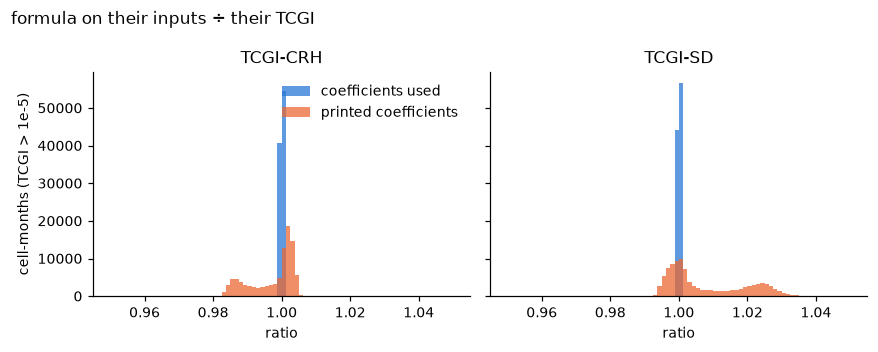

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(8, 3.2), sharey=True)
for ax, kind in zip(axes, ('CRH', 'SD')):
    t = ds[f'TCGI_{kind}_theirs'].values.ravel()
    for v, color, label in (
        ('formula', OURS, 'coefficients used'),
        ('published', THEIRS, 'printed coefficients'),
    ):
        r = ds[f'TCGI_{kind}_{v}'].values.ravel() / t
        m = np.isfinite(r) & (t > 1e-5)
        ax.hist(r[m], bins=np.linspace(0.95, 1.05, 81), color=color, alpha=0.75, label=label)
    ax.set_title(f'TCGI-{kind}')
    ax.set_xlabel('ratio')
axes[0].set_ylabel('cell-months (TCGI > 1e-5)')
axes[0].legend(frameon=False)
fig.suptitle('formula on their inputs ÷ their TCGI', x=0.01, ha='left')
fig.tight_layout()

In [5]:
pd.DataFrame(
    {
        kind: {
            'coefficients used': float(
                ds[f'TCGI_{kind}_formula'].sum() / ds[f'TCGI_{kind}_theirs'].sum()
            ),
            'printed coefficients': float(
                ds[f'TCGI_{kind}_published'].sum() / ds[f'TCGI_{kind}_theirs'].sum()
            ),
        }
        for kind in ('CRH', 'SD')
    }
).style.format('{:.4f}').set_caption('2017 global total on their inputs, ÷ theirs')

,CRH,SD
coefficients used,1.0000,1.0000
printed coefficients,0.9862,1.0246


## 2. The inputs

We rebuild each input from ERA5 monthly means on the CDS and sample it at their cell centres,
which are nodes of the ERA5 grids, so their bilinear regrid is a point sample there.
Statistics are over all valid cell-months, and over the genesis region, the cell-months
that carry 99% of their TCGI.

In [6]:
FIELDS = {
    'avor': ('850 hPa absolute vorticity', '1e-5 s⁻¹'),
    'vws': ('250–850 hPa shear', 'm s⁻¹'),
    'PI': ('potential intensity', 'm s⁻¹'),
    'CRH': ('column relative humidity', '%'),
    'SD': ('saturation deficit', 'kg m⁻²'),
}


def stats(o, t, where):
    o, t = o.where(where).values, t.where(where).values
    m = np.isfinite(o) & np.isfinite(t)
    d = o[m] - t[m]
    return {
        'bias': d.mean(),
        'rms': np.sqrt((d**2).mean()),
        'rms / sd': np.sqrt((d**2).mean()) / t[m].std(),
        'r': np.corrcoef(o[m], t[m])[0, 1],
    }


rows = []
for region, where in (('all', valid), ('genesis', genesis)):
    for v, (name, unit) in FIELDS.items():
        scale = 1e5 if v == 'avor' else 1
        rows.append(
            {
                'cells': region,
                'field': name,
                'unit': unit,
                **stats(scale * ds[f'{v}_ours'], scale * ds[f'{v}_theirs'], where),
            }
        )
(
    pd.DataFrame(rows)
    .set_index(['cells', 'field'])
    .style.format({'bias': '{:+.3g}', 'rms': '{:.3g}', 'rms / sd': '{:.4f}', 'r': '{:.6f}'})
)

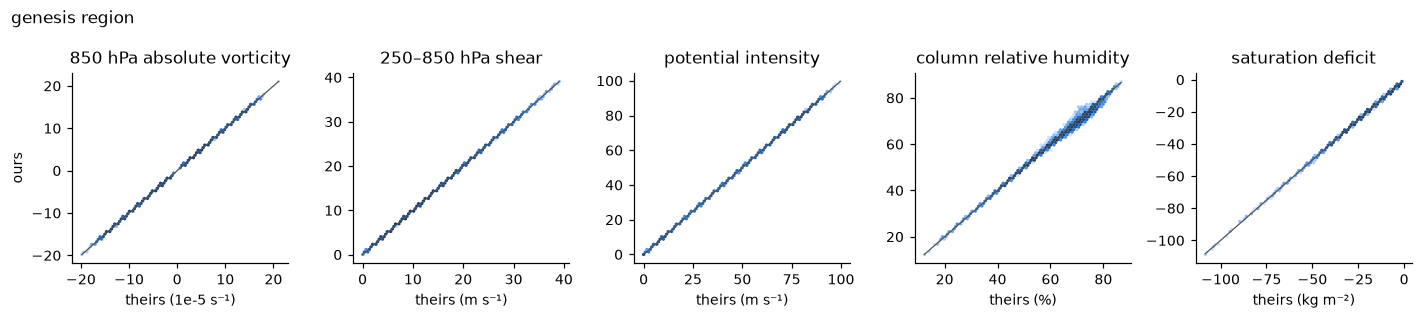

In [7]:
fig, axes = plt.subplots(1, 5, figsize=(13, 2.9))
for ax, (v, (name, unit)) in zip(axes, FIELDS.items()):
    scale = 1e5 if v == 'avor' else 1
    o, t = (
        scale * ds[f'{v}_ours'].where(genesis).values.ravel(),
        scale * ds[f'{v}_theirs'].where(genesis).values.ravel(),
    )
    m = np.isfinite(o) & np.isfinite(t)
    ax.hexbin(t[m], o[m], gridsize=60, bins='log', cmap=SEQ, mincnt=1, linewidths=0)
    lo, hi = np.percentile(t[m], [0, 100])
    ax.plot([lo, hi], [lo, hi], color='#52514e', lw=0.8)
    ax.set_title(name)
    ax.set_xlabel(f'theirs ({unit})')
axes[0].set_ylabel('ours')
fig.suptitle('genesis region', x=0.01, ha='left')
fig.tight_layout()

### Vorticity, shear and mask

ERA5 also publishes vorticity, computed spectrally. It is much further from theirs than
MetPy's finite differences of the monthly-mean winds; near the equator, where f is small,
that difference moves TCGI by tens of percent. Shear at 200 hPa, as Fosu et al. print,
does not match; 250 hPa does.

In [8]:
def era5(name):
    return tcgi._era5(tcgi.path(f'{tcgi.ERA5}/2017/{name}'))


at = {'lat': ds.lat.values, 'lon': ds.lon.values}
wind = era5('pl_wind_025.nc').sel(at).load().rename(time='month').assign_coords(month=ds.month)
f = 2 * 7.2921e-5 * np.sin(np.deg2rad(ds.lat))
alts = {
    'vorticity: MetPy (used)': (ds['avor_ours'], ds['avor_theirs'], 1e5),
    'vorticity: ERA5 spectral vo + f': (
        wind['vo'].sel(level=850, drop=True) + f,
        ds['avor_theirs'],
        1e5,
    ),
    'shear: 250–850 hPa (used)': (ds['vws_ours'], ds['vws_theirs'], 1),
    'shear: 200–850 hPa': (
        tcgi.wind_shear(
            *(wind[c].sel(level=lev, drop=True) for lev in (200, 850) for c in ('u', 'v'))
        ),
        ds['vws_theirs'],
        1,
    ),
}
rows = []
for name, (o, t, scale) in alts.items():
    row = {'input': name}
    for region, where in (('all', valid), ('genesis', genesis)):
        row[f'rms, {region}'] = stats(scale * o, scale * t, where)['rms']
    rows.append(row)
display(
    pd.DataFrame(rows)
    .set_index('input')
    .style.format('{:.3g}')
    .set_caption('vorticity in 1e-5 s⁻¹, shear in m s⁻¹')
)
ocean = ds['ocean'].values
print(
    f'mask: ours and theirs agree on {(ocean == valid.values).mean():.4%} of cell-months '
    f'({int((ocean != valid.values).sum())} differ)'
)

,"rms, all","rms, genesis"
input,,
vorticity: MetPy (used),0.00527,0.00147
vorticity: ERA5 spectral vo + f,0.196,0.0729
shear: 250–850 hPa (used),0.000586,0.000583
shear: 200–850 hPa,2.51,2.39


mask: ours and theirs agree on 99.9938% of cell-months (12 differ)


### Moisture

CRH and SD come from two columns, water vapour W and its saturation value W\*:
CRH = 100 W / W\*, SD = W − W\*. Their files determine both: W = SD / (1 − 100 / CRH),
W\* = W − SD. Their W is ERA5's total column water vapour (`tcwv`), so only W\* is in
question. The table compares ways of computing W\* from the monthly-mean temperature profile,
by W\* error and by the TCGI they give with our other inputs.

In [9]:
sl = era5('sl_025.nc').sel(at).load().rename(time='month').assign_coords(month=ds.month)
t = era5('pl_tq_1deg.nc')['t'].sel(at).load().rename(time='month').assign_coords(month=ds.month)
w = sl['tcwv']
ps = sl['sp'] / 100
w_theirs = ds['SD_theirs'] / (1 - 100 / ds['CRH_theirs'])
ws_theirs = w_theirs - ds['SD_theirs']
print('W, ERA5 tcwv vs theirs:', {k: f'{v:.2g}' for k, v in stats(w, w_theirs, valid).items()})


def to_1000(x, ps):  # trapezoid to 1000 hPa keeping levels below ground, then to a higher surface
    x = x.sortby('level').sel(level=slice(100, 1000))
    v = xr.apply_ufunc(np.trapezoid, x, x['level'] * 100, input_core_dims=[['level'], ['level']])
    return (v + ((ps - 1000) * 100).clip(min=0) * x.sel(level=1000)) / tcgi.G


def ice(t, p):
    tc = t - 273.15
    return 0.622 * 6.112 * np.exp(22.46 * tc / (tc + 272.62)) / p


rh = xr.open_dataset(tcgi.path(f'{tcgi.TUTORIAL}/relative_humidity_2017.nc')).rename(
    latitude='lat', longitude='lon'
)
rh = rh['r'].sel(at).rename(time='month').assign_coords(month=ds.month)
p = t['level']
msl = sl['msl'] / 100
VARIANTS = {
    'dilute, to sea level, top 100 hPa (used)': tcgi.column_to_surface(
        tcgi.saturation_humidity(t, p), msl, 100
    ),
    'dilute, to sea level, top 50 hPa': tcgi.column_to_surface(
        tcgi.saturation_humidity(t, p), msl, 50
    ),
    'exact, to sea level, top 100 hPa': tcgi.column_to_surface(
        tcgi.saturation_humidity(t, p, dilute=False), msl, 100
    ),
    'dilute, to surface, top 100 hPa': tcgi.column_to_surface(
        tcgi.saturation_humidity(t, p), ps, 100
    ),
    'dilute, to 1000 hPa, top 100 hPa': to_1000(tcgi.saturation_humidity(t, p), ps),
    'exact, to surface, top 100 hPa': tcgi.column_to_surface(
        tcgi.saturation_humidity(t, p, dilute=False), ps, 100
    ),
    'exact, to 1000 hPa, top 100 hPa': to_1000(tcgi.saturation_humidity(t, p, dilute=False), ps),
    'dilute, to surface, top 150 hPa': tcgi.column_to_surface(
        tcgi.saturation_humidity(t, p), ps, 150
    ),
    'dilute, to surface, top 200 hPa': tcgi.column_to_surface(
        tcgi.saturation_humidity(t, p), ps, 200
    ),
    'over ice, to surface, top 100 hPa': tcgi.column_to_surface(ice(t, p), ps, 100),
    'W / mean ERA5 RH (500–850 hPa)': w / (rh.sel(level=[500, 700, 850]).mean('level') / 100),
}


def score(ws):
    row = {f'W* {k}': v for k, v in stats(ws, ws_theirs, genesis).items() if k in ('bias', 'rms')}
    for kind, mv in (('CRH', 100 * w / ws), ('SD', w - ws)):
        ours = tcgi.tcgi(ds['avor_ours'], mv, ds['PI_ours'], ds['vws_ours'], kind).where(genesis)
        theirs = ds[f'TCGI_{kind}_theirs'].where(genesis)
        row[f'TCGI-{kind} total'] = float(ours.sum() / theirs.sum())
        row[f'TCGI-{kind} weighted |log ratio|'] = float(
            (theirs * np.abs(np.log(ours / theirs))).sum() / theirs.sum()
        )
    return row


(
    pd.DataFrame({name: score(ws) for name, ws in VARIANTS.items()})
    .T.rename_axis('W*')
    .style.format('{:.4g}')
    .set_caption('genesis region; W* in kg m⁻²')
)

W, ERA5 tcwv vs theirs: {'bias': '-2e-06', 'rms': '0.00031', 'rms / sd': '2e-05', 'r': '1'}


,W* bias,W* rms,TCGI-CRH total,TCGI-CRH weighted |log ratio|,TCGI-SD total,TCGI-SD weighted |log ratio|
W*,,,,,,
"dilute, to sea level, top 100 hPa (used)",0.02163,0.2039,1.011,0.01321,1.011,0.0122
"dilute, to sea level, top 50 hPa",0.1104,0.3259,1.009,0.01277,1.01,0.01119
"exact, to sea level, top 100 hPa",0.3617,0.414,0.968,0.03274,0.9695,0.03115
"dilute, to surface, top 100 hPa",0.008058,0.4616,1.012,0.0145,1.012,0.01334
"dilute, to 1000 hPa, top 100 hPa",0.0814,0.3683,1.011,0.01528,1.012,0.01337
"exact, to surface, top 100 hPa",0.348,0.5758,0.969,0.03274,0.9704,0.03119
"exact, to 1000 hPa, top 100 hPa",0.4216,0.512,0.9682,0.03353,0.9701,0.03122
"dilute, to surface, top 150 hPa",-0.04352,0.4456,1.013,0.01463,1.013,0.01379
"dilute, to surface, top 200 hPa",-0.1017,0.4507,1.017,0.01717,1.016,0.01633


We also tried averaging W\* over 6-hourly profiles instead of computing it from the
monthly mean, for August 2017:

In [10]:
aug = 7
h6 = xr.concat(
    [tcgi._era5(tcgi.path(f'{tcgi.VALIDATION}/era5-201708-6h/{k}.nc')) for k in 'abcd'], 'time'
).sortby('time')
h6 = h6['t'].sel(at).load()
ws_6h = tcgi.column_to_surface(
    tcgi.saturation_humidity(h6, h6['level']), msl.isel(month=aug, drop=True), 100
).mean('time')
ws_mm = VARIANTS['dilute, to sea level, top 100 hPa (used)'].isel(month=aug, drop=True)
g_aug = genesis.isel(month=aug, drop=True)
target = ws_theirs.isel(month=aug, drop=True)
(
    pd.DataFrame(
        {
            'monthly-mean T (used)': stats(ws_mm, target, g_aug),
            'mean of 6-hourly W*': stats(ws_6h, target, g_aug),
        }
    )
    .T[['bias', 'rms']]
    .style.format('{:+.3f}')
    .set_caption(f'W* − theirs, August 2017, genesis region, {h6.sizes["time"]} steps, kg m⁻²')
)

,bias,rms
monthly-mean T (used),+0.047,+0.218
mean of 6-hourly W*,+0.399,+0.599


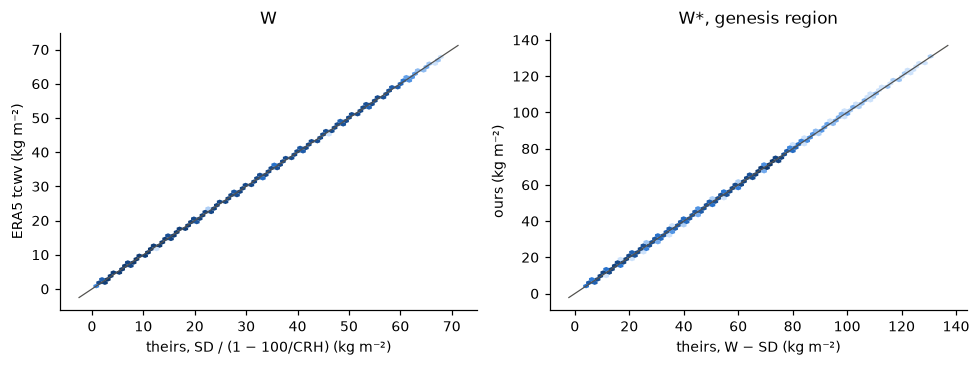

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4))
m = valid.values
axes[0].hexbin(
    w_theirs.values[m], w.values[m], gridsize=60, bins='log', cmap=SEQ, mincnt=1, linewidths=0
)
axes[0].set(title='W', xlabel='theirs, SD / (1 − 100/CRH) (kg m⁻²)', ylabel='ERA5 tcwv (kg m⁻²)')
g_ = genesis.values
axes[1].hexbin(
    ws_theirs.values[g_],
    VARIANTS['dilute, to sea level, top 100 hPa (used)'].values[g_],
    gridsize=60,
    bins='log',
    cmap=SEQ,
    mincnt=1,
    linewidths=0,
)
axes[1].set(title='W*, genesis region', xlabel='theirs, W − SD (kg m⁻²)', ylabel='ours (kg m⁻²)')
for ax in axes:
    lo, hi = ax.get_xlim()
    ax.plot([lo, hi], [lo, hi], color='#52514e', lw=0.8)
fig.tight_layout()

W is exact. No W\* variant reproduces theirs exactly:

- Integrating down to mean sea-level pressure instead of the surface pressure halves the W\* rms
  in the genesis region (0.20 against 0.46 kg m⁻²), with little bias. The CHAZ forcing lists
  give sea-level pressure, not surface pressure (Frieler et al. 2025, Table 6).
- Exact or dilute saturation humidity is the choice that moves TCGI most, about 4% on the total
  (1.011 against 0.968).
- The column top (50–200 hPa) moves the total by under 1%.
- Saturation over ice and ERA5's relative humidity are far off, and averaging 6-hourly W\* raises
  the August bias from 0.05 to 0.40 kg m⁻².

We use the dilute form, 100 hPa down to sea level. It is a provisional match for one year, not
CHAZ's method identified.

## 3. TCGI from our inputs

What matters downstream is the seeding rate, by month and by basin.

In [12]:
import shapely
from shapely.geometry import Polygon

# Meiler's basin outlines (CHAZ-hazard-maps, CHAZ-pre-processing/freq_corr.py), longitudes -180..180
EP_NA = [(-100, 60), (-100, 18), (-90, 18), (-90, 15), (-85, 15), (-85, 9), (-75, 9), (-75, 5)]
POLYS = {
    'North Atlantic': Polygon(EP_NA + [(0, 5), (0, 60)]),
    'East Pacific': Polygon([(-180, 60), (-180, 5)] + EP_NA[::-1]),
}
BOXES = {
    'North Indian': (30, 100, 5, 60),
    'South Indian': (10, 135, -60, -5),
    'West Pacific': (100, 180, 5, 60),
    'South Pacific': (135, 240, -60, -5),
}


def basin_mask(name, lat, lon):
    if name in POLYS:
        return xr.DataArray(
            shapely.contains_xy(POLYS[name], ((lon + 180) % 360 - 180).values, lat.values),
            coords=lat.coords,
        )
    w, e, s, n = BOXES[name]
    return (lon >= w) & (lon < e) & (lat >= s) & (lat <= n)


rows = []
for basin in [*POLYS, *BOXES, 'global']:
    m = True if basin == 'global' else basin_mask(basin, lat2, lon2)
    row = {'basin': basin}
    for kind in ('CRH', 'SD'):
        t, o = (
            float(ds[f'TCGI_{kind}_theirs'].where(m).sum()),
            float(ds[f'TCGI_{kind}_ours'].where(m).sum()),
        )
        row[f'{kind} theirs'], row[f'{kind} ours'], row[f'{kind} ratio'] = t, o, o / t
    rows.append(row)
pd.DataFrame(rows).set_index('basin').style.format('{:.3f}').set_caption(
    '2017 TCGI totals (seeds per year before CHAZ rescales them)'
)

,CRH theirs,CRH ours,CRH ratio,SD theirs,SD ours,SD ratio
basin,,,,,,
North Atlantic,13.845,13.978,1.010,14.746,14.898,1.010
East Pacific,16.496,16.675,1.011,15.459,15.619,1.010
North Indian,5.130,5.163,1.006,4.903,4.937,1.007
South Indian,20.140,20.338,1.010,21.384,21.598,1.010
West Pacific,34.738,35.163,1.012,32.671,33.076,1.012
South Pacific,28.162,28.543,1.014,27.853,28.225,1.013
global,123.634,124.957,1.011,122.689,124.053,1.011


In [13]:
def weighted_quantiles(x, w, q):
    i = np.argsort(x)
    c = np.cumsum(w[i]) / w.sum()
    return np.interp(q, c, x[i])


rows = []
for kind in ('CRH', 'SD'):
    t, o = ds[f'TCGI_{kind}_theirs'].values, ds[f'TCGI_{kind}_ours'].values
    for label, m, weighted in (
        ('genesis cell-months', genesis.values & np.isfinite(o), False),
        ('cell-months with TCGI > 1e-3', (t > 1e-3) & np.isfinite(o), False),
        ('genesis, weighted by their TCGI', genesis.values & np.isfinite(o), True),
    ):
        r, wt = o[m] / t[m], (t[m] if weighted else np.ones(m.sum()))
        within = wt[(r >= 0.99) & (r <= 1.03)].sum() / wt.sum()
        q5, q50, q95 = weighted_quantiles(r, wt, [0.05, 0.5, 0.95])
        rows.append(
            {
                'TCGI': kind,
                'over': label,
                '5%': q5,
                'median': q50,
                '95%': q95,
                'share within −1% / +3%': within,
            }
        )
pd.DataFrame(rows).set_index(['TCGI', 'over']).style.format('{:.3f}').set_caption(
    'ours ÷ theirs, per cell-month'
)

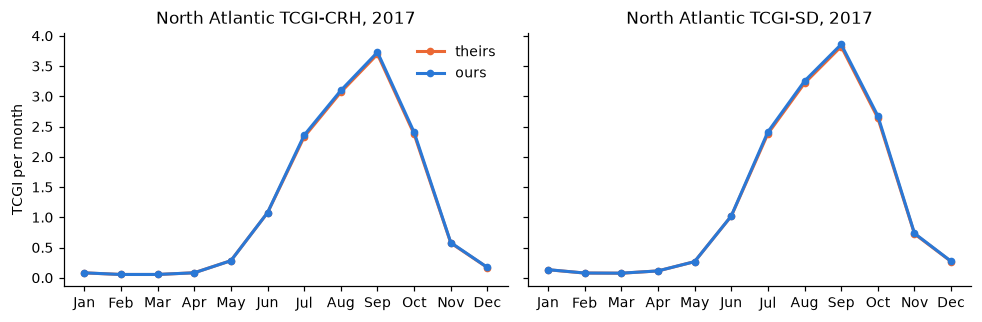

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3), sharey=True)
na = basin_mask('North Atlantic', lat2, lon2)
for ax, kind in zip(axes, ('CRH', 'SD')):
    for v, color in (('theirs', THEIRS), ('ours', OURS)):
        ax.plot(
            MONTHS,
            ds[f'TCGI_{kind}_{v}'].where(na).sum(('lat', 'lon')),
            color=color,
            lw=2,
            marker='o',
            ms=4,
            label=v,
        )
    ax.set_title(f'North Atlantic TCGI-{kind}, 2017')
axes[0].set_ylabel('TCGI per month')
axes[0].legend(frameon=False)
fig.tight_layout()

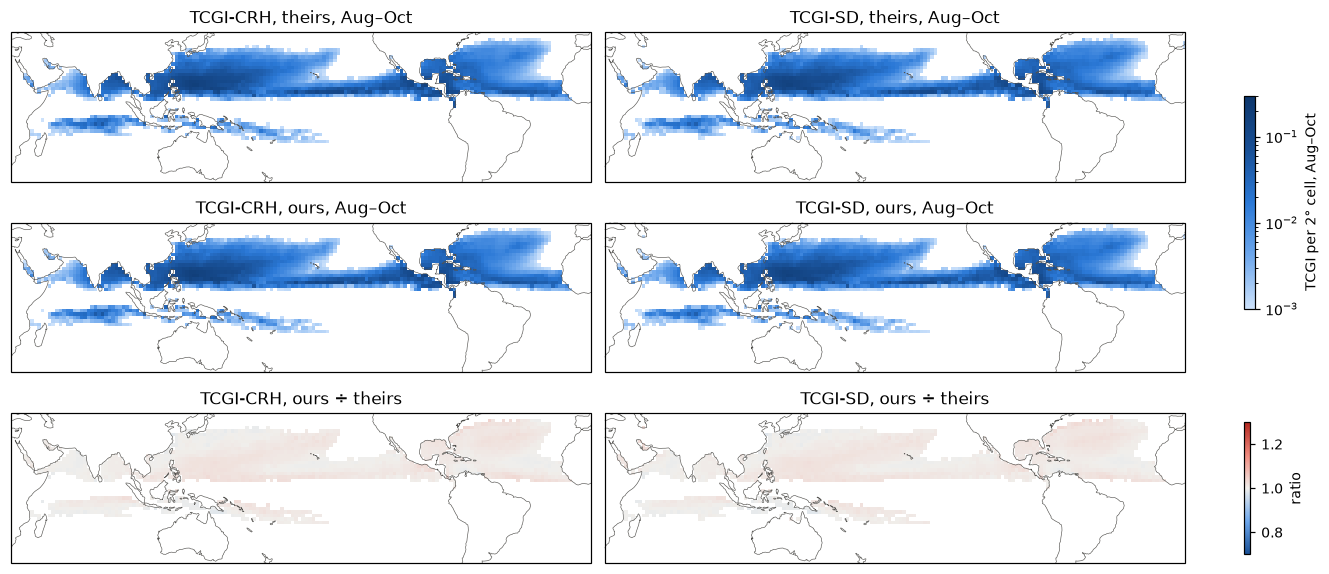

In [15]:
aso = slice(7, 10)  # Aug–Oct
proj = ccrs.PlateCarree(central_longitude=180)
fig, axes = plt.subplots(
    3, 2, figsize=(12, 5.2), subplot_kw={'projection': proj}, layout='constrained'
)
for col, kind in enumerate(('CRH', 'SD')):
    t = ds[f'TCGI_{kind}_theirs'].isel(month=aso).sum('month', min_count=1)
    o = ds[f'TCGI_{kind}_ours'].isel(month=aso).sum('month', min_count=1)
    norm = LogNorm(1e-3, 0.3)
    for row, (field, title) in enumerate(((t, 'theirs'), (o, 'ours'))):
        im = field.where(field > 1e-3).plot(
            ax=axes[row, col], transform=ccrs.PlateCarree(), cmap=SEQ, norm=norm, add_colorbar=False
        )
        axes[row, col].set_title(f'TCGI-{kind}, {title}, Aug–Oct')
    ratio = (o / t).where(t > 1e-3)
    im2 = ratio.plot(
        ax=axes[2, col],
        transform=ccrs.PlateCarree(),
        cmap=DIV,
        norm=TwoSlopeNorm(1, 0.7, 1.3),
        add_colorbar=False,
    )
    axes[2, col].set_title(f'TCGI-{kind}, ours ÷ theirs')
fig.colorbar(im, ax=axes[:2, :], shrink=0.6, label='TCGI per 2° cell, Aug–Oct')
fig.colorbar(im2, ax=axes[2, :], shrink=0.8, label='ratio')
for ax in axes.flat:
    ax.coastlines(lw=0.4, color='#52514e')
    ax.set_extent([30, 359.9, -40, 45], ccrs.PlateCarree())

## 4. Seeding

CHAZ seeds rint(ratio × global TCGI) storm precursors each month, with one ratio per run. In the public
code the ratio is observed storms 1981–2005, divided by a survival rate of 0.78, over the seeds TCGI
gives at ratio 1. The published ERA5 track files hold the storms CHAZ kept, not its seeds: its writer
drops storms seeded within 2° of the equator or outside every basin, so counts differ between files
where the seed counts cannot. We apply the rule forward to our TCGI and compare with those counts,
using the share of seeds our own CHAZ port keeps (`tcgi.py seeding`).

In [16]:
table = pd.read_csv(tcgi.path(f'{tcgi.VALIDATION}/seeding_1981_2005.csv'), index_col='year')
observed = json.loads(tcgi.path(f'{tcgi.VALIDATION}/seeding_1981_2005.json').read_text())[
    'observed_storms_per_year_1981_2005'
]
port = pd.read_csv(tcgi.path(f'{tcgi.VALIDATION}/chaz_port_2017_storms.csv'))
kept = port['storms_kept'].sum() / port['seeds'].sum()
files = table[[f'file_{i}' for i in range(10)]]
published = files.mean(axis=1)
years = table.index[table.index <= 2005]
monthly = {k: table[[f'TCGI_{k}_m{m:02d}' for m in range(1, 13)]].values for k in ('CRH', 'SD')}
rows = {}
for kind, m in monthly.items():
    ratio = observed / tcgi.SURVIVAL / tcgi.seeds(m[: len(years)], 1.0).mean()
    expected = kept * tcgi.seeds(m, ratio)
    rows[f'TCGI-{kind}'] = {
        'r, published counts vs our TCGI': np.corrcoef(published, m.sum(axis=1))[0, 1],
        'ratio, code rule': ratio,
        'seeds/yr 1981–2005 at that ratio': tcgi.seeds(m[: len(years)], ratio).mean(),
        'published storms/yr 1981–2005': published.loc[years].mean(),
        'published ÷ seeds': published.loc[years].mean()
        / tcgi.seeds(m[: len(years)], ratio).mean(),
        'published ÷ expected kept, yearly sd': (published / expected).std(),
    }
print(
    f'observed storms 1981–2005 (tutorial best-track file): {observed:.1f}/yr; '
    f'our CHAZ port keeps {kept:.3f} of its seeds (ERA5 2017, {len(port)} realizations); '
    f'spread between published files, median over years: {(files.max(axis=1) - files.min(axis=1)).median():.0f} storms'
)
pd.DataFrame(rows).T.style.format('{:.3f}').set_caption(f'{len(table)} years: 1981–2005 and 2017')

observed storms 1981–2005 (tutorial best-track file): 98.1/yr; our CHAZ port keeps 0.967 of its seeds (ERA5 2017, 40 realizations); spread between published files, median over years: 6 storms


,"r, published counts vs our TCGI","ratio, code rule",seeds/yr 1981–2005 at that ratio,published storms/yr 1981–2005,published ÷ seeds,"published ÷ expected kept, yearly sd"
TCGI-CRH,0.987,1.183,125.760,121.188,0.964,0.021
TCGI-SD,0.977,1.153,126.160,121.188,0.961,0.033


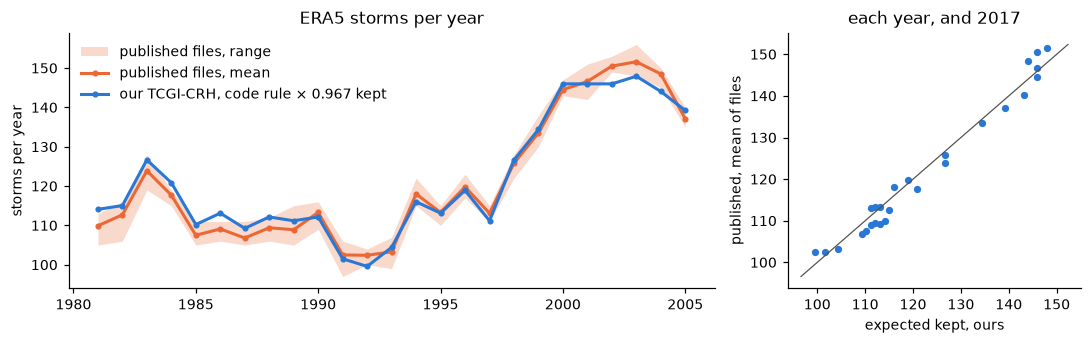

In [17]:
ratio = observed / tcgi.SURVIVAL / tcgi.seeds(monthly['CRH'][: len(years)], 1.0).mean()
expected = kept * tcgi.seeds(monthly['CRH'], ratio)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2), gridspec_kw={'width_ratios': [2.2, 1]})
axes[0].fill_between(
    years,
    files.loc[years].min(axis=1),
    files.loc[years].max(axis=1),
    color=THEIRS,
    alpha=0.25,
    lw=0,
    label='published files, range',
)
axes[0].plot(
    years, published.loc[years], color=THEIRS, lw=2, marker='o', ms=3, label='published files, mean'
)
axes[0].plot(
    years,
    expected[: len(years)],
    color=OURS,
    lw=2,
    marker='o',
    ms=3,
    label=f'our TCGI-CRH, code rule × {kept:.3f} kept',
)
axes[0].set(ylabel='storms per year', title='ERA5 storms per year')
axes[0].legend(frameon=False)
axes[1].scatter(expected, published, color=OURS, s=14)
lo, hi = expected.min() * 0.97, expected.max() * 1.03
axes[1].plot([lo, hi], [lo, hi], color='#52514e', lw=0.8)
axes[1].set(
    xlabel='expected kept, ours', ylabel='published, mean of files', title='each year, and 2017'
)
fig.tight_layout()

## Summary and open items

From ERA5 monthly means, our 2017 TCGI is 1.1% above the tutorial's globally and 0.6–1.4% above in
every basin, for both moisture variables. Weighted by their TCGI, 97% (CRH) and 98% (SD) of the
genesis rate sits in cell-months within −1% and +3% of theirs; by count of cell-months it is 64%
and 71%, the rest being cells with little TCGI. The formula, vorticity, shear, PI and mask
reproduce exactly or nearly so; W\* is the one input we approximate, and it accounts for the 1.1%.

Over 1981–2005 and 2017, the storms per year in the published ERA5 track files follow our TCGI
(r = 0.987 for CRH, 0.977 for SD), so our TCGI tracks theirs year to year, not only in 2017. The
public code's seeding rule, applied to our TCGI-CRH, gives 126 seeds a year over 1981–2005; the
published files hold 121, a share of 0.964, close to the 0.967 our own CHAZ port keeps after dropping
storms seeded near the equator or outside every basin. The counts are therefore consistent with the
public rule. They agree more closely with TCGI-CRH than with TCGI-SD, but do not by themselves show
which the ERA5 run used.

Open:

- **W\*.** The exact definition is unknown; the dilute form to sea level is fit to this one year.
- **ERA5 run configuration.** CRH or SD, and the exact best-track count behind the seeding ratio,
  are for the CHAZ authors to confirm.
- **CMIP6.** This checks ERA5 only. For GCM forcing the CHAZ team adds the 1981–2010 ERA5
  climatology to each model's anomalies of the four TCGI fields, on a 2° grid (Camargo et al.
  2025, §4c; Fosu et al. 2024, §2.2). The next notebook covers it.